# Assistente de Atendimento em Saneamento com PLN
### Trabalho 2 — Tópicos em Computação · IFSP São Carlos

**Tema:** chatbot / sistema de perguntas e respostas sobre documentos de um serviço municipal de saneamento (SAAE São Carlos).

**Ideia central.** Um munícipe escreve uma pergunta ("cortaram minha água, como religo?"). O sistema:

1. **classifica a intenção** da mensagem (7 classes de atendimento) — *PLN tradicional*;
2. **busca os trechos mais relevantes** do corpus (resoluções, manuais, históricos de atendimento) — *PLN tradicional (TF-IDF / BM25)*;
3. **somente no final**, um modelo de linguagem redige a resposta a partir desses trechos (RAG) — *componente contemporâneo*.

| Etapa do enunciado | Onde está neste caderno |
|---|---|
| 1 — Corpus | Seção 1 |
| 2 — Processamento | Seção 2 |
| 3 — Modelo principal (classificação + busca textual) | Seção 3 |
| 4 — Avaliação (métricas, matriz de confusão, erros, baseline) | Seção 4 |
| 5 — Visualização (≥ 4) | Figuras 1–9, distribuídas + Seção 5 |
| 6 — Componente contemporâneo (embeddings contextuais + RAG) | Seção 6 |

> Este trabalho reaproveita o corpus construído no TCC *"Chatbot com IA para Atendimento em Saneamento: Análise de Viabilidade Técnica e Econômica"*, com uma diferença: os históricos reais de atendimento foram substituídos por **históricos sintéticos derivados deles**, sem dados pessoais. Assim, todo o corpus é público e o caderno é 100% reproduzível. A extração dos PDFs públicos e o OCR estão no caderno `01_construcao_corpus.ipynb`; este caderno parte dos arquivos `.txt` em `dados/corpus_txt/`.

## 0. Configuração

**Antes de executar no Colab**

1. Os 48 `.txt` do corpus devem estar em `MyDrive/trabalho_TCP2/Arquivo/dados/corpus_txt/` (a mesma pasta `dados/corpus_txt` do repositório).
2. Os arquivos `perguntas_intencao.csv` e `perguntas_busca.csv` ficam em `MyDrive/trabalho_TCP2/Arquivo/dados/`. Se faltar algum arquivo, o caderno **para com uma mensagem** — ele nunca roda com dados de exemplo.
3. A chave da Groq **não** fica no código: no Colab, abra o ícone de chave (🔑 *Secrets*) e crie `GROQ_API_KEY`.

In [31]:
import sys, subprocess, os
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "rank_bm25", "sentence-transformers", "groq", "wordcloud", "unidecode"], check=True)
    subprocess.run([sys.executable, "-m", "spacy", "download", "pt_core_news_sm", "-q"], check=True)
print("Ambiente:", "Colab" if IN_COLAB else "local")

Ambiente: Colab


In [32]:
import re, json, time, warnings, unicodedata
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk, spacy
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer
from unidecode import unidecode

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)
from sklearn.decomposition import TruncatedSVD, NMF
from rank_bm25 import BM25Okapi

warnings.filterwarnings("ignore")
nltk.download("stopwords", quiet=True)
nltk.download("rslp", quiet=True)
nlp = spacy.load("pt_core_news_sm", disable=["parser", "ner"])

SEED = 42
np.random.seed(SEED)

# Paleta (categórica, ordem fixa) e estilo dos gráficos
AZUL, LARANJA, VERDE_AGUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CINZA = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9.5,
})

# Caminhos — estrutura da pasta no Google Drive:
#   MyDrive/trabalho_TCP2/Arquivo/dados/                          → CSVs de perguntas e gabarito
#   MyDrive/trabalho_TCP2/Arquivo/dados/corpus_txt/               → os 48 .txt do corpus
#   MyDrive/trabalho_TCP2/Arquivo/resultados/                     → figuras e tabelas geradas (criada sozinha)
if IN_COLAB:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/trabalho_TCP2")
    PASTA_DADOS = BASE / "Arquivo" / "dados"
    PASTA_TXT = PASTA_DADOS / "corpus_txt"
    PASTA_RES = BASE / "Arquivo" / "resultados"
else:                                   # execução local (repositório clonado)
    PASTA_DADOS = Path("dados")
    PASTA_TXT = Path("dados/corpus_txt")
    PASTA_RES = Path("resultados")
PASTA_RES.mkdir(parents=True, exist_ok=True)

# Falha cedo e com mensagem clara se algo estiver fora do lugar (nunca usar dados de exemplo)
for arq in ["perguntas_intencao.csv", "perguntas_busca.csv"]:
    assert (PASTA_DADOS / arq).exists(), f"Não encontrei {PASTA_DADOS / arq} — confira a pasta."
assert any(PASTA_TXT.glob("*.txt")), f"Nenhum .txt encontrado em {PASTA_TXT} — confira os caminhos."
print("Perguntas lidas de:", PASTA_DADOS)
print("Resultados salvos em:", PASTA_RES)
print("Corpus lido de:", PASTA_TXT)

Perguntas lidas de: /content/drive/MyDrive/trabalho_TCP2/Arquivo/dados
Resultados salvos em: /content/drive/MyDrive/trabalho_TCP2/Arquivo/resultados
Corpus lido de: /content/drive/MyDrive/trabalho_TCP2/Arquivo/dados/corpus_txt


## 1. Corpus (Etapa 1)

### 1.1 Origem

O trabalho usa **dois conjuntos de dados**, cada um ligado a uma tarefa:

**(A) Corpus documental — base da busca e do RAG.** Construído no TCC, com 48 documentos:

| Categoria | Qtde | Origem | Acesso |
|---|---|---|---|
| `resolucao` | 2 | Resoluções da agência reguladora ARES-PCJ (nº 482/2023 — regulamento do SAAE; nº 724/2026 — reajuste tarifário) | Públicas, site da ARES-PCJ |
| `manual` | 2 | Folhetos da SABESP (instalação hidráulica; variação de consumo — extraído por OCR) | Públicos, site da SABESP |
| `historico` | 33 | Históricos **sintéticos** de atendimento por WhatsApp, um para cada histórico real do SAAE São Carlos (cedidos com autorização para o TCC). Cada um preserva o assunto e os procedimentos do original (documentos exigidos, prazos, custos), reescrito sem dados pessoais (`[NOME]`, `[ENDERECO]`, `[CDC]`…) | Público (repositório) |
| `sintetico` | 11 | Procedimentos escritos pelo autor a partir da experiência como atendente | Público (repositório) |

**(B) Perguntas rotuladas por intenção — base do classificador.** 154 perguntas curtas (`dados/perguntas_intencao.csv`), 22 por classe, redigidas no estilo de mensagens de munícipes (inclusive sem acento e com abreviações). As classes espelham os motivos de contato mais comuns na central:

`conta_pagamento` · `consumo_tarifa` · `corte_religacao` · `falta_agua_vazamento` · `cadastro_ligacao` · `esgoto` · `fora_escopo`

A classe `fora_escopo` reúne serviços municipais que **não** são do SAAE (IPTU, iluminação, lixo) — é o que permite ao chatbot reconhecer quando não deve responder.

**(C) Perguntas de busca** (`dados/perguntas_busca.csv`): 25 perguntas, incluindo as 10 usadas na avaliação do TCC, usadas para medir a qualidade da recuperação.

In [33]:
def categoria_de(nome):
    for prefixo, cat in [("historico", "historico"), ("saae_sint", "sintetico"),
                         ("resolucao", "resolucao"), ("manual", "manual")]:
        if nome.startswith(prefixo):
            return cat
    return "outro"

RE_CABECALHO = re.compile(r"^\[CORPUS SINTÉTICO \| (.*?) \| (.*?)\]\s*\n?")

registros = []
for arq in sorted(PASTA_TXT.glob("*.txt")):
    texto = arq.read_text(encoding="utf-8")
    sub = ""
    m = RE_CABECALHO.match(texto)
    if m:                      # o cabeçalho vira metadado, não conteúdo
        sub = f"{m.group(1)} / {m.group(2)}"
        texto = texto[m.end():]
    registros.append({"arquivo": arq.name, "categoria": categoria_de(arq.name),
                      "subcategoria": sub, "texto_bruto": texto,
                      "n_palavras": len(texto.split())})

corpus = pd.DataFrame(registros)
ORDEM_CAT = ["resolucao", "manual", "historico", "sintetico"]
resumo = (corpus.groupby("categoria")
          .agg(documentos=("arquivo", "count"), palavras=("n_palavras", "sum"),
               media_palavras=("n_palavras", "mean"), mediana=("n_palavras", "median"))
          .reindex(ORDEM_CAT).dropna(how="all").round(0))
resumo["% palavras"] = (100 * resumo["palavras"] / resumo["palavras"].sum()).round(1)
print(f"{len(corpus)} documentos · {corpus.n_palavras.sum():,} palavras".replace(",", "."))
RE_DADO_PESSOAL = re.compile(r"\b\d{5,6}-\d{2}\b|\d{3}\.\d{3}\.\d{3}-\d{2}|[\w.]+@[\w.]+")
print("Trechos com cara de CDC, CPF ou e-mail no corpus:", sum(len(RE_DADO_PESSOAL.findall(t)) for t in corpus.texto_bruto))
resumo

48 documentos · 24.623 palavras
Trechos com cara de CDC, CPF ou e-mail no corpus: 0


,documentos,palavras,media_palavras,mediana,% palavras
categoria,,,,,
resolucao,2,16528,8264.0,8264.0,67.1
manual,2,2098,1049.0,1049.0,8.5
historico,33,4596,139.0,129.0,18.7
sintetico,11,1401,127.0,134.0,5.7


In [34]:
perguntas = pd.read_csv(PASTA_DADOS / "perguntas_intencao.csv")
perguntas_busca = pd.read_csv(PASTA_DADOS / "perguntas_busca.csv")
ORDEM_INT = ["conta_pagamento", "consumo_tarifa", "corte_religacao", "falta_agua_vazamento",
             "cadastro_ligacao", "esgoto", "fora_escopo"]
print(f"Perguntas de intenção: {len(perguntas)} | Perguntas de busca: {len(perguntas_busca)}")
perguntas.groupby("intencao").pergunta.agg(["count", lambda s: s.iloc[0]]).rename(
    columns={"count": "n", "<lambda_0>": "exemplo"}).reindex(ORDEM_INT)

Perguntas de intenção: 154 | Perguntas de busca: 25


,n,exemplo
intencao,,
conta_pagamento,22,Como tiro a segunda via da conta de água?
consumo_tarifa,22,"Minha conta veio muito alta esse mês, por quê?"
corte_religacao,22,"Cortaram minha água, como faço para religar?"
falta_agua_vazamento,22,Estou sem água desde manhã
cadastro_ligacao,22,Como faço para pedir uma ligação nova de água?
esgoto,22,O esgoto está voltando pelo ralo
fora_escopo,22,Como pago o IPTU?


**Figura 1 — Composição das classes.** Quantos documentos e quantas palavras cada categoria contribui, e a distribuição das perguntas por intenção.

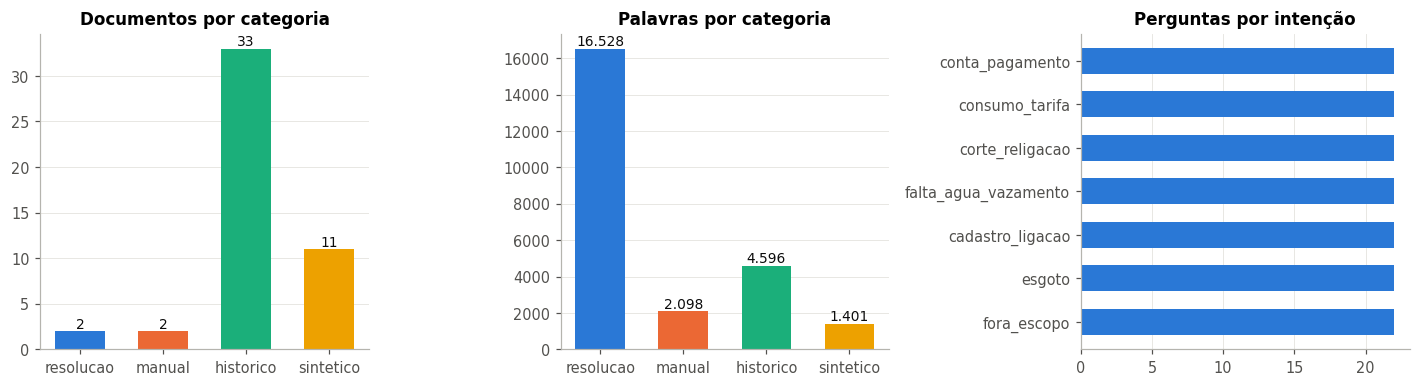

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
cats = resumo.index.tolist()
cores_cat = {"resolucao": AZUL, "manual": LARANJA, "historico": VERDE_AGUA, "sintetico": AMARELO}

for a, col, titulo in [(ax[0], "documentos", "Documentos por categoria"),
                       (ax[1], "palavras", "Palavras por categoria")]:
    vals = resumo[col].values
    a.bar(cats, vals, color=[cores_cat[c] for c in cats], width=0.6)
    for i, v in enumerate(vals):
        a.text(i, v, f"{int(v):,}".replace(",", "."), ha="center", va="bottom", fontsize=9, color="#0b0b0b")
    a.set_title(titulo); a.grid(axis="x", visible=False)

cont = perguntas.intencao.value_counts().reindex(ORDEM_INT)
ax[2].barh(cont.index[::-1], cont.values[::-1], color=AZUL, height=0.6)
ax[2].set_title("Perguntas por intenção"); ax[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(PASTA_RES / "fig1_classes.png", bbox_inches="tight"); plt.show()

### 1.2 Análise das classes, viés e limitações

**Desequilíbrio no corpus documental.** Em número de documentos, os históricos dominam (33 de 48); em volume de texto, a resolução 482/2023 sozinha concentra boa parte das palavras. Isso tem duas consequências: (i) métodos baseados em frequência tendem a "puxar" trechos do regulamento para perguntas genéricas; (ii) a divisão em *chunks* de tamanho fixo transforma o regulamento em muitos trechos, aumentando a chance de ele aparecer no top-k só por volume.

**Viés de fonte.** Os manuais são da SABESP, não do SAAE — procedimentos e canais podem diferir. Por isso o texto passa por substituição de nome e telefone antes da indexação (herdado do TCC).

**Viés das perguntas rotuladas.** As 154 perguntas foram **redigidas pelo autor** com base na experiência na central, e não coletadas de munícipes. Elas são mais "limpas" e mais balanceadas (22 por classe) que a demanda real, em que contas e falta de água predominam. As métricas do classificador são, portanto, um **limite otimista**. Uma extensão natural é rotular falas reais extraídas dos 33 históricos como conjunto de teste externo.

**Sobreposição entre classes.** Algumas fronteiras são genuinamente ambíguas: *"conta alta, pode ser vazamento?"* é `consumo_tarifa` ou `falta_agua_vazamento`? *"ligação de esgoto"* é `esgoto` ou `cadastro_ligacao`? Essas ambiguidades aparecem na análise de erros (Seção 4).

**Privacidade e reprodutibilidade.** Os históricos reais (cedidos pelo SAAE para o TCC) continham nomes, endereços e números de cadastro digitados pelos munícipes dentro das mensagens, que a anonimização automática não conseguia remover com segurança. Por orientação do professor, eles foram substituídos por **33 históricos sintéticos derivados**: um para cada atendimento real, com o mesmo assunto e as mesmas informações de procedimento, mas reescritos com outras palavras e com marcadores no lugar dos dados pessoais. O custo é perder parte da "naturalidade" da fala real (erros de digitação, mensagens truncadas); o ganho é um corpus 100% publicável e um experimento reproduzível por qualquer pessoa. As mensagens repetitivas do menu automático, que nos dados reais apareciam em todos os atendimentos, foram mantidas só quando trazem informação de procedimento.

## 2. Processamento (Etapa 2)

Pipeline aplicado **igualmente** a documentos e perguntas:

| Passo | O que faz | Por quê |
|---|---|---|
| Limpeza | remove marcadores de dados pessoais (`[NOME]`, `[ENDERECO]`, `[CDC]`, `[CPF]`…), URLs, "Página x de y", símbolos | ruído de extração/anonimização |
| Anonimização de fonte | troca "SABESP" e telefones pela central local | herdado do TCC |
| Normalização | minúsculas; expansão de abreviações do domínio (`2ª via → segunda via`, `m³ → metro cúbico`, `vc → você`); remoção de números soltos | munícipes escrevem de formas variadas |
| Tokenização | spaCy `pt_core_news_sm` | tokenizador treinado para português |
| Stopwords | lista NLTK (207 palavras) **mantendo negações** (`não`, `sem`, `nem`) + stopwords do domínio (saudações e falas de cortesia) | "**sem** água" ≠ "água" |
| Stemming / Lematização | RSLP (NLTK) **ou** lemas do spaCy; depois remoção de acentos | comparar as duas abordagens |
| Representação | Bag-of-Words, TF-IDF e BM25 | Seção 3 |

In [36]:
RE_PLACEHOLDER = re.compile(r"\[(TELEFONE|PROTOCOLO|EMAIL|CPF|NOME|ENDERECO|CDC)\]")
RE_URL = re.compile(r"https?://\S+|www\.\S+")
RE_PAGINA = re.compile(r"p[áa]gina\s+\d+\s+de\s+\d+", re.I)

def anonimizar_fonte(t):
    t = re.sub(r"Companhia de Saneamento B[áa]sico do Estado de S[ãa]o Paulo", "a empresa", t, flags=re.I)
    t = re.sub(r"\bSABESP\b", "a empresa", t, flags=re.I)
    t = re.sub(r"\b0800[\s\-]?\d{3}[\s\-]?\d{4}\b", "a central de atendimento", t)
    t = re.sub(r"\(?\d{2}\)?\s?\d{4,5}[-\s]?\d{4}", "a central de atendimento", t)
    return t

def limpar(t):
    t = anonimizar_fonte(t)
    t = RE_PLACEHOLDER.sub(" ", t)
    t = RE_URL.sub(" ", t)
    t = RE_PAGINA.sub(" ", t)
    t = re.sub(r"[^\w\sà-ÿÀ-ß.,;:?!ºª³%-]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

ABREVIACOES = [
    (r"\b2\s*[ªa°]?\s*via\b", "segunda via"), (r"\bm\s*³|\bm3\b", "metro cúbico"),
    (r"\bvc\b", "você"), (r"\bpq\b", "porque"), (r"\bq\b", "que"), (r"\btá\b|\bta\b", "está"),
    (r"\bpra\b", "para"), (r"\bn[ºo°]\b", "número"),
]
def normalizar(t):
    t = t.lower()
    for padrao, subst in ABREVIACOES:
        t = re.sub(padrao, subst, t)
    t = re.sub(r"\d+([.,]\d+)*", " ", t)        # números soltos
    return re.sub(r"\s+", " ", t).strip()

NEGACOES = {"não", "sem", "nem"}
STOP_DOMINIO = {"bom", "dia", "tarde", "noite", "obrigado", "obrigada", "senhor", "senhora",
                "sr", "sra", "ok", "né", "aí", "então", "atendente", "cliente", "gostaria",
                "favor", "por", "aguarde", "momento", "certo", "tudo", "bem",
                # verbos genéricos (como lemas): aparecem em quase toda frase e não distinguem assuntos
                "poder", "dever", "fazer", "querer", "ficar", "haver", "ter", "ser", "estar", "ir"}
STOPWORDS = (set(stopwords.words("portuguese")) - NEGACOES) | STOP_DOMINIO
STOPWORDS_SEM_ACENTO = {unidecode(w) for w in STOPWORDS}
stemmer = RSLPStemmer()

def _tokens_spacy(texto_norm):
    return [t for t in nlp(texto_norm) if t.is_alpha and len(t.text) > 1]

def preprocessar(texto, modo="lema"):
    '''modo: "cru" (só tokeniza), "stop" (+stopwords), "stem" (+RSLP), "lema" (+spaCy)'''
    toks = _tokens_spacy(normalizar(limpar(texto)))
    if modo == "cru":
        return [unidecode(t.text) for t in toks]
    toks = [t for t in toks if t.text not in STOPWORDS]
    if modo == "stop":
        return [unidecode(t.text) for t in toks]
    if modo == "stem":
        return [unidecode(stemmer.stem(t.text)) for t in toks]
    if modo == "lema":
        lemas = [unidecode(t.lemma_.lower()) for t in toks]
        return [l for l in lemas if l not in STOPWORDS_SEM_ACENTO]
    raise ValueError(modo)

exemplo = "Bom dia! Cortaram minha água ontem, já paguei a 2ª via. Qdo religam? Tel [TELEFONE]"
print("Original    :", exemplo)
print("Limpo       :", limpar(exemplo))
print("Normalizado :", normalizar(limpar(exemplo)))
for modo in ["cru", "stop", "stem", "lema"]:
    print(f"{modo:<12}:", preprocessar(exemplo, modo))

Original    : Bom dia! Cortaram minha água ontem, já paguei a 2ª via. Qdo religam? Tel [TELEFONE]
Limpo       : Bom dia! Cortaram minha água ontem, já paguei a 2ª via. Qdo religam? Tel
Normalizado : bom dia! cortaram minha água ontem, já paguei a segunda via. qdo religam? tel
cru         : ['bom', 'dia', 'cortaram', 'minha', 'agua', 'ontem', 'ja', 'paguei', 'segunda', 'via', 'qdo', 'religam', 'tel']
stop        : ['cortaram', 'agua', 'ontem', 'paguei', 'segunda', 'via', 'qdo', 'religam', 'tel']
stem        : ['cort', 'agu', 'ont', 'pag', 'segund', 'via', 'qdo', 'relig', 'tel']
lema        : ['cortar', 'agua', 'ontem', 'paguei', 'segundo', 'via', 'qdo', 'religar', 'tel']


### 2.1 Segmentação em trechos (*chunks*)

Documentos longos (o regulamento tem dezenas de páginas) são divididos em janelas de **200 palavras com sobreposição de 50**, sobre o texto apenas *limpo* (legível). O pré-processamento é aplicado depois, sobre cada trecho. No TCC os trechos eram de 500 palavras sem sobreposição; trechos menores deixam a busca mais precisa e o contexto enviado ao LLM mais enxuto.

In [37]:
TAM_CHUNK, SOBREPOSICAO = 200, 50

chunks = []
for _, doc in corpus.iterrows():
    palavras = limpar(doc.texto_bruto).split()
    passo = TAM_CHUNK - SOBREPOSICAO
    for j, ini in enumerate(range(0, max(len(palavras) - SOBREPOSICAO, 1), passo)):
        chunks.append({"chunk_id": f"{Path(doc.arquivo).stem}#{j}", "arquivo": doc.arquivo,
                       "categoria": doc.categoria, "texto": " ".join(palavras[ini:ini + TAM_CHUNK])})
chunks = pd.DataFrame(chunks)

t0 = time.time()
for modo in ["cru", "stop", "stem", "lema"]:
    chunks[f"tok_{modo}"] = [preprocessar(t, modo) for t in chunks.texto]
    perguntas[f"tok_{modo}"] = [preprocessar(t, modo) for t in perguntas.pergunta]
    perguntas_busca[f"tok_{modo}"] = [preprocessar(t, modo) for t in perguntas_busca.pergunta]
print(f"{len(chunks)} trechos gerados de {len(corpus)} documentos ({time.time()-t0:.1f}s de pré-processamento)")
chunks.groupby("categoria").size().reindex(ORDEM_CAT).rename("trechos").to_frame().T

175 trechos gerados de 48 documentos (28.4s de pré-processamento)


categoria,resolucao,manual,historico,sintetico
trechos,112,15,37,11


In [38]:
estagios = []
for modo, rotulo in [("cru", "Tokenização"), ("stop", "+ stopwords"), ("stem", "+ stemming RSLP"), ("lema", "+ lematização")]:
    todos = [t for lst in chunks[f"tok_{modo}"] for t in lst]
    estagios.append({"estágio": rotulo, "modo": modo, "tokens": len(todos), "vocabulário": len(set(todos))})
estagios = pd.DataFrame(estagios)
estagios["redução do vocab. (%)"] = (100 * (1 - estagios["vocabulário"] / estagios["vocabulário"].iloc[0])).round(1)
estagios

,estágio,modo,tokens,vocabulário,redução do vocab. (%)
0,Tokenização,cru,25416,3226,0.0
1,+ stopwords,stop,17258,3101,3.9
2,+ stemming RSLP,stem,17258,1763,45.4
3,+ lematização,lema,16834,2334,27.7


**Figura 2 — Efeito do pré-processamento.** À esquerda, os termos mais frequentes antes e depois da remoção de stopwords; à direita, o tamanho do vocabulário a cada estágio.

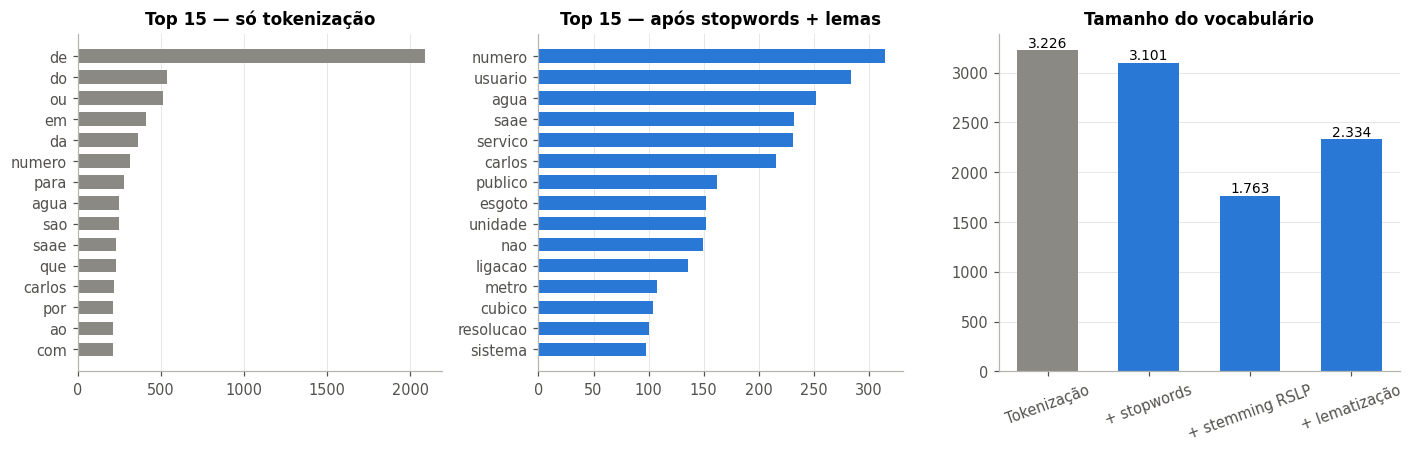

In [39]:
fig = plt.figure(figsize=(13, 4.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.1])
for k, (modo, titulo, cor) in enumerate([("cru", "Top 15 — só tokenização", CINZA),
                                         ("lema", "Top 15 — após stopwords + lemas", AZUL)]):
    a = fig.add_subplot(gs[0, k])
    top = Counter(t for lst in chunks[f"tok_{modo}"] for t in lst).most_common(15)[::-1]
    a.barh([w for w, _ in top], [c for _, c in top], color=cor, height=0.65)
    a.set_title(titulo); a.grid(axis="y", visible=False)
a = fig.add_subplot(gs[0, 2])
a.bar(estagios["estágio"], estagios["vocabulário"], color=[CINZA, AZUL, AZUL, AZUL], width=0.6)
for i, v in enumerate(estagios["vocabulário"]):
    a.text(i, v, f"{v:,}".replace(",", "."), ha="center", va="bottom", fontsize=9)
a.set_title("Tamanho do vocabulário"); a.tick_params(axis="x", rotation=20); a.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(PASTA_RES / "fig2_preprocessamento.png", bbox_inches="tight"); plt.show()

### 2.2 Representação textual

Os tokens já pré-processados alimentam três representações:

- **Bag-of-Words** (`CountVectorizer`) — contagem; base do Naive Bayes;
- **TF-IDF** (`TfidfVectorizer`, unigramas + bigramas, `sublinear_tf`) — pondera termos raros; base da regressão logística, SVM e busca por cosseno;
- **BM25** (`rank_bm25`) — variação probabilística do TF-IDF com saturação de frequência e normalização por tamanho do documento; padrão em motores de busca.

Abaixo, os termos de maior peso TF-IDF médio em cada categoria do corpus — uma primeira leitura do que distingue cada fonte.

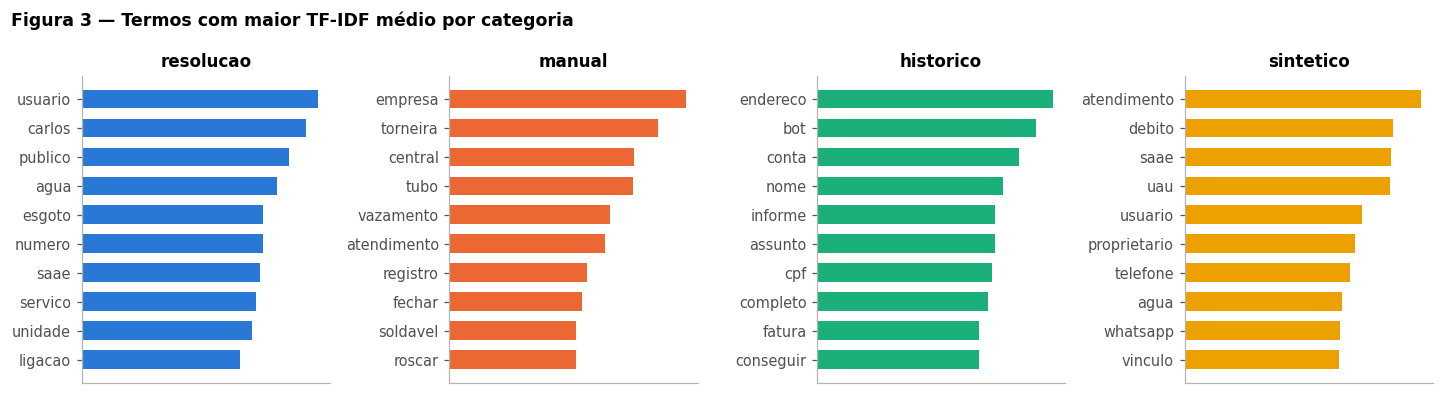

In [40]:
identidade = lambda toks: toks          # os textos já chegam tokenizados

tfidf_cat = TfidfVectorizer(analyzer=identidade, sublinear_tf=True, min_df=1)
X_cat = tfidf_cat.fit_transform(chunks.tok_lema)
vocab = np.array(tfidf_cat.get_feature_names_out())
cats_presentes = [c for c in ORDEM_CAT if c in chunks.categoria.values]

fig, ax = plt.subplots(1, len(cats_presentes), figsize=(3.3 * len(cats_presentes), 3.6))
ax = np.atleast_1d(ax)
for a, cat in zip(ax, cats_presentes):
    media = np.asarray(X_cat[(chunks.categoria == cat).values].mean(axis=0)).ravel()
    idx = media.argsort()[::-1][:10][::-1]
    a.barh(vocab[idx], media[idx], color=cores_cat[cat], height=0.65)
    a.set_title(cat); a.grid(axis="y", visible=False); a.set_xticks([])
fig.suptitle("Figura 3 — Termos com maior TF-IDF médio por categoria", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(PASTA_RES / "fig3_tfidf_categoria.png", bbox_inches="tight"); plt.show()

## 3. Modelo principal (Etapa 3)

Duas abordagens do enunciado, que correspondem às duas primeiras peças do chatbot:

- **3A — Classificação** da intenção da pergunta (roteamento: responder, ou encaminhar se `fora_escopo`);
- **3B — Busca textual / similaridade** entre a pergunta e os trechos do corpus.

### 3A. Classificação de intenção

Modelos clássicos sobre BoW/TF-IDF. Como a base é pequena (154 exemplos), a avaliação usa **validação cruzada estratificada com 5 partições**: cada pergunta é prevista por um modelo que não a viu no treino, e todas as 154 entram nas métricas.

In [41]:
y = perguntas.intencao.values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def tfidf():
    return TfidfVectorizer(analyzer=lambda toks: toks + [f"{a}_{b}" for a, b in zip(toks, toks[1:])],
                           sublinear_tf=True)

MODELOS = {
    "Naive Bayes (BoW)":        lambda: make_pipeline(CountVectorizer(analyzer=identidade), MultinomialNB(alpha=0.5)),
    "Regressão Logística (TF-IDF)": lambda: make_pipeline(tfidf(), LogisticRegression(C=10, max_iter=2000)),
    "SVM linear (TF-IDF)":      lambda: make_pipeline(tfidf(), LinearSVC(C=1.0)),
}
print("Modelos definidos:", ", ".join(MODELOS))

Modelos definidos: Naive Bayes (BoW), Regressão Logística (TF-IDF), SVM linear (TF-IDF)


### 3B. Busca textual

Cada pergunta é pré-processada pelo mesmo pipeline e comparada a todos os trechos. O resultado é uma lista ordenada de **documentos** (o trecho de maior pontuação representa seu documento).

In [42]:
class Buscador:
    '''Interface comum: pontuar(tokens_pergunta) -> vetor de pontuações por trecho.'''
    def ranking_docs(self, tokens, k=5):
        s = self.pontuar(tokens)
        ordem = np.argsort(-s)
        docs, vistos = [], set()
        for i in ordem:
            arq = chunks.arquivo.iat[i]
            if arq not in vistos:
                vistos.add(arq); docs.append((arq, float(s[i]), int(i)))
            if len(docs) == k:
                break
        return docs

class BuscaJaccard(Buscador):
    '''Referência ingênua: sobreposição de palavras, sem pesos.'''
    def __init__(self, coluna):
        self.col = coluna; self.conj = [set(t) for t in chunks[coluna]]
    def pontuar(self, toks):
        q = set(toks)
        return np.array([len(q & c) / (len(q | c) or 1) for c in self.conj])

class BuscaTFIDF(Buscador):
    def __init__(self, coluna):
        self.col = coluna
        self.vec = TfidfVectorizer(analyzer=identidade, sublinear_tf=True)
        self.X = self.vec.fit_transform(chunks[coluna])
    def pontuar(self, toks):
        return (self.X @ self.vec.transform([toks]).T).toarray().ravel()

class BuscaBM25(Buscador):
    def __init__(self, coluna):
        self.col = coluna; self.bm = BM25Okapi(list(chunks[coluna]))
    def pontuar(self, toks):
        return np.asarray(self.bm.get_scores(toks))

BUSCADORES = {
    "Jaccard (cru) — referência": BuscaJaccard("tok_cru"),
    "TF-IDF + stemming":          BuscaTFIDF("tok_stem"),
    "TF-IDF + lemas":             BuscaTFIDF("tok_lema"),
    "BM25 + stemming":            BuscaBM25("tok_stem"),
    "BM25 + lemas":               BuscaBM25("tok_lema"),
}

def mostrar_busca(pergunta, nome="BM25 + lemas", k=3):
    b = BUSCADORES[nome]
    toks = preprocessar(pergunta, b.col.replace("tok_", ""))
    print(f"❓ {pergunta}\n   tokens: {toks}")
    for arq, s, i in b.ranking_docs(toks, k):
        print(f"   {s:7.3f}  {arq:<45} | {chunks.texto.iat[i][:110]}…")

mostrar_busca("Cortaram minha água, como faço para religar?")

❓ Cortaram minha água, como faço para religar?
   tokens: ['cortar', 'agua', 'religar']
     6.152  resolucao_482_2023_regulamento_saae.txt       | interna ou externa ao imóvel, para receber água antes da sua passagem pelo medidor de volume hidrômetro ou reg…
     4.972  historico_sint_32.txt                         | Assunto: Revisão de conta Cliente 09:05 Desculpa a demora Bot 09:07 Motivo da revisão: 1. Vazamento 2. Aferiçã…
     4.288  historico_sint_31.txt                         | uma pedra tinha cortado a mangueira. Liguei no 0800 e me pediram para mandar as fotos por aqui. Atendente 09:2…


## 4. Avaliação (Etapa 4)

### 4.1 Classificação de intenção

**Métricas.** Acurácia e **F1-macro** (média do F1 de cada classe — não deixa uma classe fácil mascarar uma difícil).

**Abordagens de referência:**
- *Classe majoritária* (`DummyClassifier`) — o piso absoluto;
- *Regras por palavra-chave* — o equivalente a um menu de URA ("digite 1 para contas…"), que é como muitos atendimentos automáticos funcionam hoje;
- *Mesmo modelo sem pré-processamento* (tokens crus) — isola o efeito da Etapa 2.

In [43]:
REGRAS = [  # ordem importa: primeira regra que casar vence
    ("esgoto",               ["esgoto", "fossa", "bueiro", "ralo"]),
    ("corte_religacao",      ["cort", "relig", "deslig", "suspend"]),
    ("falta_agua_vazamento", ["vazament", "sem agua", "falta", "pressao", "barrent", "cano"]),
    ("consumo_tarifa",       ["tarifa", "alta", "consumo", "reajuste", "leitura"]),
    ("cadastro_ligacao",     ["titular", "ligacao", "nome", "hidrometro", "cadastro", "instalacao"]),
    ("conta_pagamento",      ["conta", "via", "boleto", "parcel", "debito", "pag"]),
]
def classificar_por_regras(texto):
    t = unidecode(normalizar(texto))
    for classe, chaves in REGRAS:
        if any(c in t for c in chaves):
            return classe
    return "fora_escopo"

resultados_clf, previsoes = [], {}
def registrar(nome, entrada, pred):
    previsoes[nome] = pred
    resultados_clf.append({"modelo": nome, "entrada": entrada,
                           "acurácia": accuracy_score(y, pred), "F1-macro": f1_score(y, pred, average="macro")})

registrar("Classe majoritária", "—", cross_val_predict(DummyClassifier(strategy="most_frequent"),
                                                       np.zeros((len(y), 1)), y, cv=cv))
registrar("Regras por palavra-chave", "texto normalizado", np.array([classificar_por_regras(t) for t in perguntas.pergunta]))

for nome, fabrica in MODELOS.items():
    for modo in ["cru", "stem", "lema"]:
        pred = cross_val_predict(fabrica(), perguntas[f"tok_{modo}"].values, y, cv=cv)
        registrar(nome, modo, pred)

tab_clf = pd.DataFrame(resultados_clf).round(3).sort_values("F1-macro", ascending=False)
tab_clf.to_csv(PASTA_RES / "classificacao_comparacao.csv", index=False)
tab_clf

,modelo,entrada,acurácia,F1-macro
1,Regras por palavra-chave,texto normalizado,0.805,0.807
10,SVM linear (TF-IDF),lema,0.688,0.683
6,Regressão Logística (TF-IDF),stem,0.688,0.683
9,SVM linear (TF-IDF),stem,0.688,0.678
7,Regressão Logística (TF-IDF),lema,0.682,0.677
3,Naive Bayes (BoW),stem,0.636,0.619
5,Regressão Logística (TF-IDF),cru,0.610,0.601
8,SVM linear (TF-IDF),cru,0.610,0.599
4,Naive Bayes (BoW),lema,0.610,0.569
2,Naive Bayes (BoW),cru,0.584,0.559


> **Atenção ao interpretar as regras.** As palavras-chave foram escritas por quem também redigiu as perguntas, olhando o conjunto inteiro — não passaram pela validação cruzada. Elas têm, portanto, uma vantagem injusta (equivalente a "treinar no teste"). Se as regras empatarem ou superarem os modelos, a leitura correta é: *com só 22 exemplos por classe, o conhecimento de domínio do atendente ainda vale mais que o aprendizado estatístico* — e isso motiva aumentar a base ou usar representações pré-treinadas (Seção 6).

**Figura 4 — Comparação dos classificadores** (F1-macro na validação cruzada). Cinza: abordagens de referência.

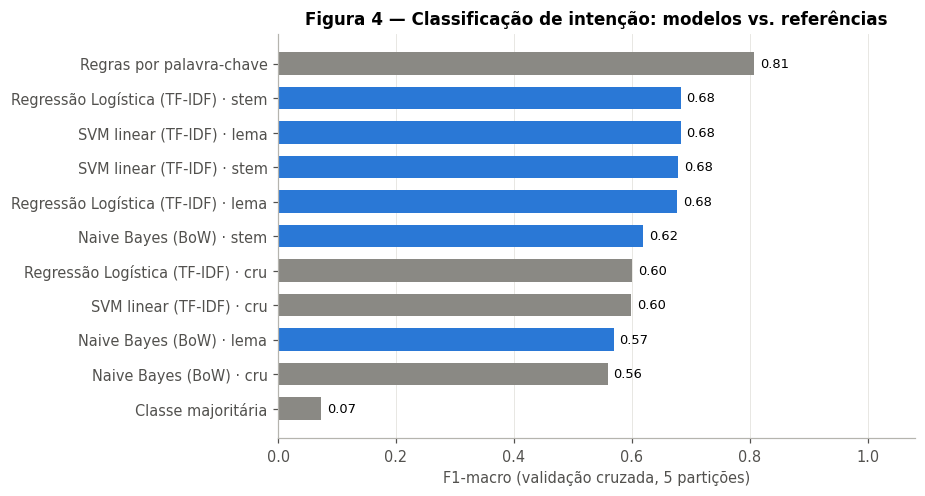

In [44]:
tab_plot = tab_clf.copy()
tab_plot["rótulo"] = tab_plot.apply(lambda r: r.modelo if r.entrada in ("—", "texto normalizado")
                                    else f"{r.modelo} · {r.entrada}", axis=1)
tab_plot = tab_plot.sort_values("F1-macro")
cores = [CINZA if r.entrada in ("—", "texto normalizado", "cru") else AZUL for r in tab_plot.itertuples()]
fig, a = plt.subplots(figsize=(8.5, 4.6))
a.barh(tab_plot["rótulo"], tab_plot["F1-macro"], color=cores, height=0.65)
for i, v in enumerate(tab_plot["F1-macro"]):
    a.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8.5)
a.set_xlim(0, 1.08); a.set_xlabel("F1-macro (validação cruzada, 5 partições)"); a.grid(axis="y", visible=False)
a.set_title("Figura 4 — Classificação de intenção: modelos vs. referências")
plt.tight_layout(); plt.savefig(PASTA_RES / "fig4_classificadores.png", bbox_inches="tight"); plt.show()

In [45]:
melhor = tab_clf[~tab_clf.entrada.isin(["—", "texto normalizado"])].iloc[0]
MELHOR_CLF, MELHOR_MODO = melhor.modelo, melhor.entrada
pred_melhor = cross_val_predict(MODELOS[MELHOR_CLF](), perguntas[f"tok_{MELHOR_MODO}"].values, y, cv=cv)
print(f"Melhor configuração: {MELHOR_CLF} com tokens '{MELHOR_MODO}'\n")
print(classification_report(y, pred_melhor, labels=ORDEM_INT, digits=3, zero_division=0))

Melhor configuração: SVM linear (TF-IDF) com tokens 'lema'

                      precision    recall  f1-score   support

     conta_pagamento      0.522     0.545     0.533        22
      consumo_tarifa      0.778     0.636     0.700        22
     corte_religacao      0.739     0.773     0.756        22
falta_agua_vazamento      0.654     0.773     0.708        22
    cadastro_ligacao      0.640     0.727     0.681        22
              esgoto      0.875     0.955     0.913        22
         fora_escopo      0.600     0.409     0.486        22

            accuracy                          0.688       154
           macro avg      0.687     0.688     0.683       154
        weighted avg      0.687     0.688     0.683       154



**Figura 5 — Matriz de confusão** do melhor classificador (contagens; diagonal = acertos).

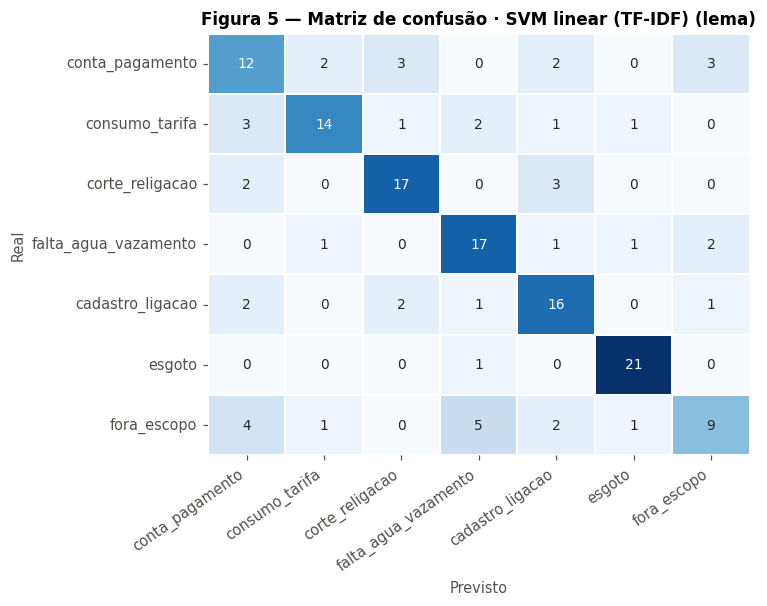

In [46]:
cm = confusion_matrix(y, pred_melhor, labels=ORDEM_INT)
fig, a = plt.subplots(figsize=(7, 5.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=1, linecolor="white",
            xticklabels=ORDEM_INT, yticklabels=ORDEM_INT, ax=a, annot_kws={"fontsize": 9})
a.set_xlabel("Previsto"); a.set_ylabel("Real"); a.grid(False)
a.set_title(f"Figura 5 — Matriz de confusão · {MELHOR_CLF} ({MELHOR_MODO})")
plt.xticks(rotation=35, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); plt.savefig(PASTA_RES / "fig5_matriz_confusao.png", bbox_inches="tight"); plt.show()

#### Análise dos erros

Abaixo, todas as perguntas classificadas errado pelo melhor modelo, e os termos de maior peso que o modelo aprendeu para cada classe (interpretabilidade). Ao apresentar, vale discutir **por que** cada erro acontece — vocabulário compartilhado entre classes, pergunta curta demais, palavra fora do vocabulário de treino, ou rótulo genuinamente ambíguo.

In [47]:
erros = perguntas.assign(previsto=pred_melhor)[lambda d: d.intencao != d.previsto][["id", "pergunta", "intencao", "previsto"]]
erros.to_csv(PASTA_RES / "classificacao_erros.csv", index=False)
print(f"{len(erros)} erros em {len(perguntas)} perguntas\n")
pd.set_option("display.max_colwidth", 80)
erros

48 erros em 154 perguntas



,id,pergunta,intencao,previsto
6,Q007,"Paguei a conta em duplicidade, como peço a devolução?",conta_pagamento,corte_religacao
10,Q011,quero o codigo de barras da fatura,conta_pagamento,fora_escopo
11,Q012,"Minha conta não chegou esse mês, o que faço?",conta_pagamento,consumo_tarifa
14,Q015,Quanto tempo depois do pagamento a conta aparece como paga?,conta_pagamento,corte_religacao
15,Q016,"Recebi aviso de débito mas já paguei, e agora?",conta_pagamento,corte_religacao
16,Q017,Como faço acordo de parcelamento de dívida antiga?,conta_pagamento,fora_escopo
17,Q018,preciso da 2 via urgente,conta_pagamento,fora_escopo
18,Q019,"A conta vem em nome de outra pessoa, consigo pagar mesmo assim?",conta_pagamento,cadastro_ligacao
19,Q020,Qual o prazo para contestar uma cobrança?,conta_pagamento,consumo_tarifa
21,Q022,Como consulto se tenho débito em aberto no imóvel?,conta_pagamento,cadastro_ligacao


In [48]:
clf_final = MODELOS[MELHOR_CLF]().fit(perguntas[f"tok_{MELHOR_MODO}"].values, y)
modelo_lin = clf_final[-1]
if hasattr(modelo_lin, "coef_"):
    nomes = np.array(clf_final[0].get_feature_names_out())
    linhas = []
    for i, classe in enumerate(modelo_lin.classes_):
        top = nomes[np.argsort(modelo_lin.coef_[i])[::-1][:8]]
        linhas.append({"classe": classe, "termos de maior peso": ", ".join(top)})
    display(pd.DataFrame(linhas).set_index("classe").reindex(ORDEM_INT))

,termos de maior peso
classe,
conta_pagamento,"conta, debito, pagar, pagar_conta, receber, receber_conta, outro, consigo"
consumo_tarifa,"tarifa, consumo, desconto, leitura, conta_vir, reajuste, reajuste_tarifa, di..."
corte_religacao,"religacao, cortar, corte, cortar_agua, agua_volta, aviso, pagamento, religac..."
falta_agua_vazamento,"agua, vazamento, hidrometro_vazar, vazar, sem_agua, todo, cano, calcada"
cadastro_ligacao,"novo, nome, preciso, ligacao_novo, ligacao, mudar, hidrometro_numero, cadastro"
esgoto,"esgoto, rede, rede_esgoto, transbordar, ligacao_esgoto, cheiro, esgoto_volta..."
fora_escopo,"luz, conta_gas, gas, onde_poupatempo, poupatempo, pagar_iptu, iptu, telefone..."


### 4.2 Busca textual

**Gabarito de relevância.** Não existe gabarito pronto de "quais documentos respondem a cada pergunta", então ele foi construído à mão: cada um dos **1.200 pares** (25 perguntas × 48 documentos) foi julgado como relevante (1) ou não (0), com o critério *"esse documento ajudaria a atendente a responder?"*. O julgamento foi pré-anotado com assistência e revisado pelo autor. Por ser **exaustivo** (todos os pares, e não só os mais bem colocados), nenhum método é favorecido por ter seus resultados julgados e os de outros não. O arquivo fica em `dados/relevancia_anotada.csv`.

> A célula abaixo ainda gera `resultados/pool_para_anotar.csv` (os 5 primeiros documentos de cada método), útil se novas perguntas forem acrescentadas.

**Métricas** (nível de documento): *Acerto@1* (o primeiro resultado é relevante?), *Revocação@3* e *Revocação@5* (fração dos documentos relevantes que aparecem no top-k) e **MRR** (média de 1/posição do primeiro relevante).

In [49]:
# Embeddings contextuais são definidos aqui só para participarem do pooling;
# a análise deles está na Seção 6.
MODELOS_EMB = {
    "Embeddings BERTimbau (TCC)": "neuralmind/bert-base-portuguese-cased",
    "Embeddings MiniLM multilíngue": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
}
_cache_emb = {}
def carregar_embedder(nome_hf):
    if nome_hf not in _cache_emb:
        from sentence_transformers import SentenceTransformer
        _cache_emb[nome_hf] = SentenceTransformer(nome_hf)
    return _cache_emb[nome_hf]

class BuscaEmbeddings(Buscador):
    col = "texto"
    def __init__(self, nome_hf):
        self.modelo = carregar_embedder(nome_hf)
        self.E = self.modelo.encode(chunks.texto.tolist(), normalize_embeddings=True,
                                    batch_size=16, show_progress_bar=False)
    def pontuar_texto(self, texto):
        q = self.modelo.encode([limpar(texto)], normalize_embeddings=True)[0]
        return self.E @ q                       # cosseno (vetores normalizados)

BUSCADORES_EMB = {}
for nome, hf in MODELOS_EMB.items():
    try:
        BUSCADORES_EMB[nome] = BuscaEmbeddings(hf)
        print("✅", nome)
    except Exception as e:
        print(f"⚠️ {nome} indisponível ({type(e).__name__}) — seguirá só com métodos tradicionais.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Embeddings BERTimbau (TCC)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Embeddings MiniLM multilíngue


In [50]:
def ranking(nome, pergunta, k=5):
    if nome in BUSCADORES_EMB:
        b = BUSCADORES_EMB[nome]; s = b.pontuar_texto(pergunta)
    else:
        b = BUSCADORES[nome]; s = b.pontuar(preprocessar(pergunta, b.col.replace("tok_", "")))
    ordem, docs, vistos = np.argsort(-s), [], set()
    for i in ordem:
        arq = chunks.arquivo.iat[i]
        if arq not in vistos:
            vistos.add(arq); docs.append((arq, int(i)))
        if len(docs) == k: break
    return docs

ARQ_GABARITO = PASTA_DADOS / "relevancia_anotada.csv"
todos_metodos = list(BUSCADORES) + list(BUSCADORES_EMB)

pool = []
for _, q in perguntas_busca.iterrows():
    candidatos = {}
    for nome in todos_metodos:
        for arq, i in ranking(nome, q.pergunta, 5):
            candidatos.setdefault(arq, i)
    for arq, i in candidatos.items():
        pool.append({"id": q.id, "pergunta": q.pergunta, "arquivo": arq,
                     "trecho": chunks.texto.iat[i][:400], "relevante": ""})
pool = pd.DataFrame(pool)
pool.to_csv(PASTA_RES / "pool_para_anotar.csv", index=False, encoding="utf-8-sig")
print(f"Pool: {len(pool)} pares pergunta–documento ({len(pool)/len(perguntas_busca):.1f} por pergunta)")

if ARQ_GABARITO.exists():
    # sep=None aceita "," (Google Planilhas) e ";" (Excel em português)
    gab = pd.read_csv(ARQ_GABARITO, sep=None, engine="python", encoding="utf-8-sig")
    gab["relevante"] = pd.to_numeric(gab["relevante"], errors="coerce").fillna(0).astype(int)
    RELEVANTES = gab[gab.relevante == 1].groupby("id").arquivo.apply(set).to_dict()
    novos = set(zip(pool.id, pool.arquivo)) - set(zip(gab.id, gab.arquivo))
    print(f"Gabarito carregado: {sum(map(len, RELEVANTES.values()))} pares relevantes em {len(RELEVANTES)} perguntas.")
    if novos:
        print(f"⚠️ {len(novos)} pares do pool atual não foram julgados (contam como não relevantes).")
else:
    RELEVANTES = None
    print("➡️  Gabarito ainda não existe: anote resultados/pool_para_anotar.csv e salve como", ARQ_GABARITO)

Pool: 320 pares pergunta–documento (12.8 por pergunta)
Gabarito carregado: 86 pares relevantes em 25 perguntas.


In [51]:
def avaliar_busca(metodos):
    linhas, por_pergunta = [], []
    for nome in metodos:
        acc = {"Acerto@1": [], "Revocação@3": [], "Revocação@5": [], "MRR": []}
        for _, q in perguntas_busca.iterrows():
            rel = RELEVANTES.get(q.id, set())
            if not rel:               # pergunta sem documento relevante no corpus
                continue
            docs = [a for a, _ in ranking(nome, q.pergunta, 5)]
            rr = next((1 / (p + 1) for p, a in enumerate(docs) if a in rel), 0.0)
            acc["Acerto@1"].append(float(docs[0] in rel))
            acc["Revocação@3"].append(len(rel & set(docs[:3])) / len(rel))
            acc["Revocação@5"].append(len(rel & set(docs[:5])) / len(rel))
            acc["MRR"].append(rr)
            por_pergunta.append({"método": nome, "id": q.id, "pergunta": q.pergunta, "RR": rr, "top1": docs[0]})
        linhas.append({"método": nome, **{k: np.mean(v) for k, v in acc.items()}})
    return pd.DataFrame(linhas).round(3), pd.DataFrame(por_pergunta)

if RELEVANTES is not None:
    sem_rel = sorted(set(perguntas_busca.id) - set(RELEVANTES))
    print("Perguntas sem nenhum documento relevante (o corpus não cobre):", sem_rel or "nenhuma")
    tab_busca, rr_busca = avaliar_busca(list(BUSCADORES))
    tab_busca.to_csv(PASTA_RES / "busca_tradicional.csv", index=False)
    display(tab_busca.sort_values("MRR", ascending=False))
else:
    print("Avaliação da busca aguardando o gabarito.")

Perguntas sem nenhum documento relevante (o corpus não cobre): nenhuma


,método,Acerto@1,Revocação@3,Revocação@5,MRR
2,TF-IDF + lemas,0.72,0.666,0.782,0.847
1,TF-IDF + stemming,0.68,0.678,0.805,0.827
4,BM25 + lemas,0.68,0.685,0.772,0.817
3,BM25 + stemming,0.64,0.639,0.742,0.798
0,Jaccard (cru) — referência,0.40,0.375,0.507,0.590


#### Análise dos erros da busca

Perguntas em que o melhor método tradicional **não** trouxe nenhum documento relevante no top-5 (RR = 0), com o documento que ele colocou em primeiro. Padrões típicos: sinônimos sem termo em comum ("religar" × "restabelecimento"), perguntas sobre algo que o corpus não contém, ou o regulamento ganhando por volume de texto.

In [52]:
if RELEVANTES is not None:
    melhor_trad = tab_busca.sort_values("MRR", ascending=False).iloc[0]["método"]
    falhas = rr_busca[(rr_busca["método"] == melhor_trad) & (rr_busca.RR == 0)]
    print(f"Método analisado: {melhor_trad} — {len(falhas)} pergunta(s) sem acerto no top-5")
    display(falhas[["id", "pergunta", "top1"]])

Método analisado: TF-IDF + lemas — 0 pergunta(s) sem acerto no top-5


,id,pergunta,top1


## 5. Visualização exploratória (Etapa 5)

Além das Figuras 1–5, duas visualizações do espaço de documentos:

- **Figura 6 — Modelagem de tópicos (NMF)** sobre os trechos: que assuntos emergem do corpus sem supervisão?
- **Figura 7 — Mapa 2D dos trechos** (SVD do TF-IDF), colorido pela fonte. Na Seção 6 o mesmo mapa é feito com embeddings, para comparar.

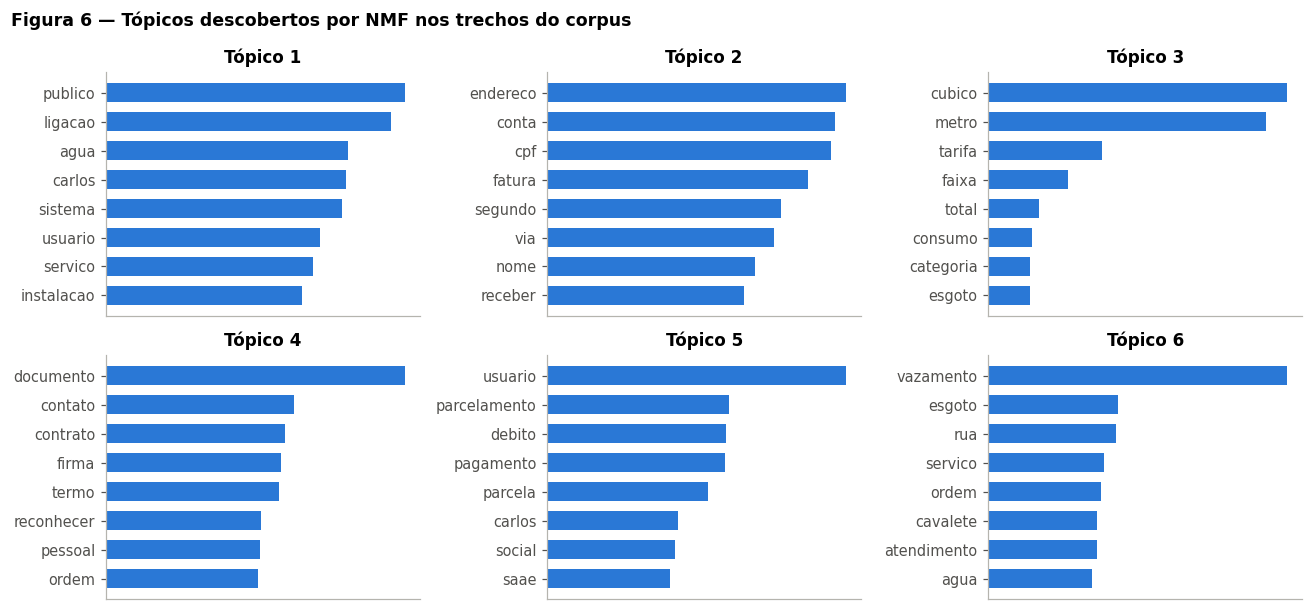

tópico,1,2,3,4,5,6
categoria,,,,,,
resolucao,52,0,12,0,47,1
manual,0,0,0,0,0,15
historico,0,17,0,10,0,10
sintetico,1,1,0,2,2,5


In [53]:
N_TOPICOS = min(6, max(2, len(chunks) // 10))
vec_nmf = TfidfVectorizer(analyzer=identidade, min_df=2, max_df=0.8)
X_nmf = vec_nmf.fit_transform(chunks.tok_lema)
nmf = NMF(n_components=N_TOPICOS, random_state=SEED, init="nndsvda", max_iter=500).fit(X_nmf)
termos = np.array(vec_nmf.get_feature_names_out())

fig, ax = plt.subplots(2, (N_TOPICOS + 1) // 2, figsize=(12, 5.6))
for t, a in enumerate(ax.ravel()):
    if t >= N_TOPICOS: a.axis("off"); continue
    idx = nmf.components_[t].argsort()[::-1][:8][::-1]
    a.barh(termos[idx], nmf.components_[t][idx], color=AZUL, height=0.65)
    a.set_title(f"Tópico {t+1}"); a.set_xticks([]); a.grid(False)
fig.suptitle("Figura 6 — Tópicos descobertos por NMF nos trechos do corpus", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(PASTA_RES / "fig6_topicos_nmf.png", bbox_inches="tight"); plt.show()

topico_dom = nmf.transform(X_nmf).argmax(axis=1)
pd.crosstab(chunks.categoria, topico_dom + 1).reindex(cats_presentes).rename_axis(columns="tópico")

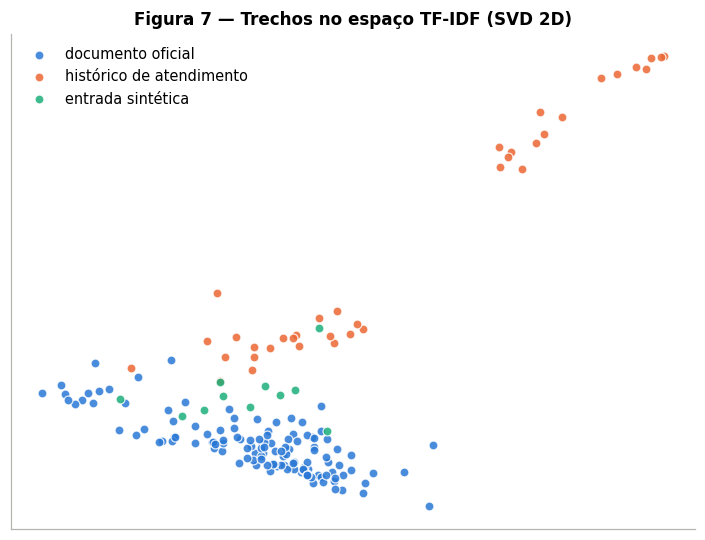

In [54]:
# Para o mapa 2D, resolução + manual viram "documento oficial" (no máx. 3 cores num gráfico de dispersão)
grupo = chunks.categoria.map({"resolucao": "documento oficial", "manual": "documento oficial",
                              "historico": "histórico de atendimento", "sintetico": "entrada sintética"})
CORES_GRUPO = {"documento oficial": AZUL, "histórico de atendimento": LARANJA, "entrada sintética": VERDE_AGUA}

def mapa_2d(ax, coords, titulo):
    for g, cor in CORES_GRUPO.items():
        m = (grupo == g).values
        ax.scatter(coords[m, 0], coords[m, 1], s=34, color=cor, label=g, alpha=0.85,
                   edgecolor="white", linewidth=0.8)
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([])

X_tfidf_chunks = BUSCADORES["TF-IDF + lemas"].X
coords_tfidf = TruncatedSVD(n_components=2, random_state=SEED).fit_transform(X_tfidf_chunks)
fig, a = plt.subplots(figsize=(6.5, 5))
mapa_2d(a, coords_tfidf, "Figura 7 — Trechos no espaço TF-IDF (SVD 2D)")
a.legend(frameon=False, loc="best")
plt.tight_layout(); plt.savefig(PASTA_RES / "fig7_mapa_tfidf.png", bbox_inches="tight"); plt.show()

## 6. Componente contemporâneo (Etapa 6)

O componente moderno entra **depois** de todo o pipeline tradicional, em duas partes:

**6.1 Embeddings contextuais (Hugging Face).** Dois modelos pré-treinados:
- `neuralmind/bert-base-portuguese-cased` (BERTimbau) — o mesmo do TCC. É um modelo de linguagem *mascarado*, não treinado para similaridade de frases; o `sentence-transformers` cria o vetor pela média dos tokens.
- `paraphrase-multilingual-MiniLM-L12-v2` — treinado especificamente para similaridade semântica, inclusive em português.

Comparamos ambos com os métodos tradicionais **no mesmo gabarito** e testamos uma **busca híbrida**: o melhor método tradicional da Seção 4.2 combinado com o MiniLM por *Reciprocal Rank Fusion*.

**6.2 Geração aumentada por recuperação (RAG).** O LLM (via API Groq) recebe a pergunta + os trechos recuperados e redige a resposta. O classificador de intenção da Seção 3A decide antes se a pergunta deve ser respondida ou encaminhada.

In [55]:
def ranking_hibrido(pergunta, nome_lex, nome_emb, k=5, profundidade=20):
    '''Reciprocal Rank Fusion: cada documento soma 1/(60 + posição) em cada lista.'''
    pont = Counter()
    for nome in (nome_lex, nome_emb):
        for pos, (arq, _) in enumerate(ranking(nome, pergunta, profundidade)):
            pont[arq] += 1 / (60 + pos)
    melhores = [a for a, _ in pont.most_common(k)]
    idx = {a: i for a, i in ranking(nome_lex, pergunta, profundidade) + ranking(nome_emb, pergunta, profundidade)}
    return [(a, idx[a]) for a in melhores]

if "_ranking_base" not in globals():
    _ranking_base = ranking
def ranking(nome, pergunta, k=5):                       # estende a função da Seção 4
    if nome.startswith("Híbrido"):
        lex, emb = nome.split(": ", 1)[1].split(" | ")
        return ranking_hibrido(pergunta, lex, emb, k)
    return _ranking_base(nome, pergunta, k)

metodos_6 = list(BUSCADORES_EMB)
if BUSCADORES_EMB:
    emb_hib = "Embeddings MiniLM multilíngue" if "Embeddings MiniLM multilíngue" in BUSCADORES_EMB else metodos_6[0]
    # o componente léxico do híbrido é o melhor método tradicional da Seção 4.2
    lex_hib = (tab_busca.sort_values("MRR", ascending=False).iloc[0]["método"]
               if RELEVANTES is not None else "BM25 + stemming")
    NOME_HIBRIDO = f"Híbrido (RRF): {lex_hib} | {emb_hib}"
    metodos_6.append(NOME_HIBRIDO)

if RELEVANTES is not None and metodos_6:
    tab_6, rr_6 = avaliar_busca(metodos_6)
    tab_todos = pd.concat([tab_busca, tab_6]).sort_values("MRR", ascending=False)
    tab_todos.to_csv(PASTA_RES / "busca_comparacao_final.csv", index=False)
    display(tab_todos)
else:
    print("Comparação aguardando gabarito e/ou modelos de embeddings.")

,método,Acerto@1,Revocação@3,Revocação@5,MRR
2,TF-IDF + lemas,0.72,0.666,0.782,0.847
2,Híbrido (RRF): TF-IDF + lemas | Embeddings MiniLM multilíngue,0.76,0.667,0.747,0.833
1,TF-IDF + stemming,0.68,0.678,0.805,0.827
4,BM25 + lemas,0.68,0.685,0.772,0.817
1,Embeddings MiniLM multilíngue,0.76,0.606,0.735,0.806
3,BM25 + stemming,0.64,0.639,0.742,0.798
0,Embeddings BERTimbau (TCC),0.40,0.440,0.557,0.627
0,Jaccard (cru) — referência,0.40,0.375,0.507,0.590


**Figura 8 — Qualidade da busca: tradicionais vs. contemporâneos** (mesmo gabarito, nível de documento).

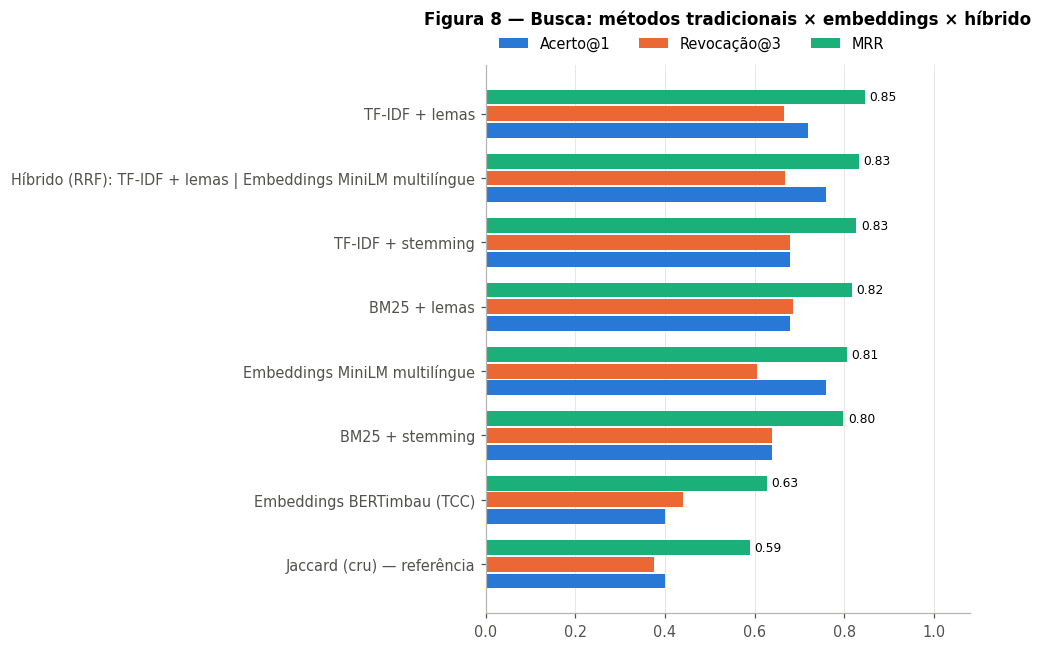

In [56]:
if RELEVANTES is not None:
    base = tab_todos if (metodos_6 and "tab_todos" in globals()) else tab_busca
    base = base.sort_values("MRR")
    metricas = ["Acerto@1", "Revocação@3", "MRR"]
    cores_m = [AZUL, LARANJA, VERDE_AGUA]
    fig, a = plt.subplots(figsize=(9, 0.55 * len(base) + 1.6))
    h = 0.26; y0 = np.arange(len(base))
    for j, (m, cor) in enumerate(zip(metricas, cores_m)):
        a.barh(y0 + (j - 1) * h, base[m], height=h - 0.03, color=cor, label=m)
    for i, v in enumerate(base["MRR"]):
        a.text(v + 0.01, i + h, f"{v:.2f}", va="center", fontsize=8)
    a.set_yticks(y0); a.set_yticklabels(base["método"]); a.set_xlim(0, 1.08)
    a.grid(axis="y", visible=False)
    a.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
    a.set_title("Figura 8 — Busca: métodos tradicionais × embeddings × híbrido", pad=26)
    plt.tight_layout(); plt.savefig(PASTA_RES / "fig8_busca_comparacao.png", bbox_inches="tight"); plt.show()

**Figura 9 — O mesmo mapa da Figura 7, agora com embeddings contextuais.** Se os grupos se separam de outra forma, o modelo está codificando algo além do vocabulário.

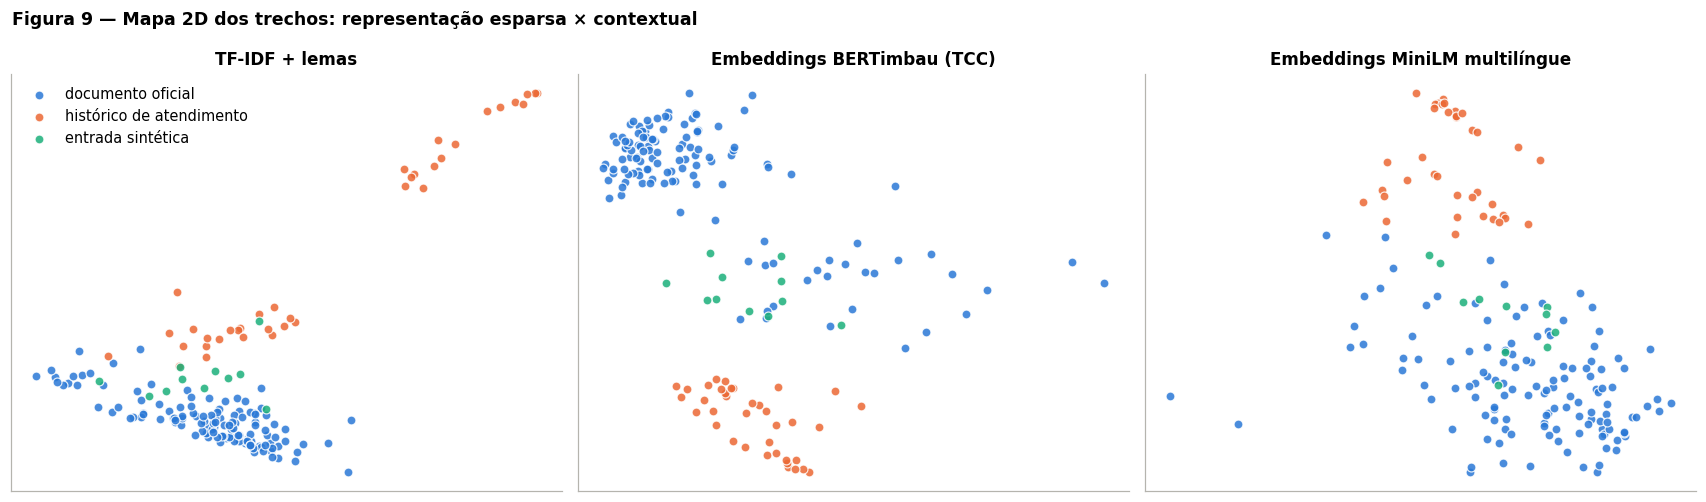

In [57]:
if BUSCADORES_EMB:
    nomes_emb = list(BUSCADORES_EMB)
    fig, ax = plt.subplots(1, 1 + len(nomes_emb), figsize=(5.2 * (1 + len(nomes_emb)), 4.6))
    mapa_2d(ax[0], coords_tfidf, "TF-IDF + lemas")
    for a, nome in zip(ax[1:], nomes_emb):
        mapa_2d(a, TruncatedSVD(n_components=2, random_state=SEED).fit_transform(BUSCADORES_EMB[nome].E), nome)
    ax[0].legend(frameon=False, loc="best")
    fig.suptitle("Figura 9 — Mapa 2D dos trechos: representação esparsa × contextual", fontweight="bold", x=0.01, ha="left")
    plt.tight_layout(); plt.savefig(PASTA_RES / "fig9_mapa_embeddings.png", bbox_inches="tight"); plt.show()

### 6.1b Classificação de intenção com embeddings

Mesmo protocolo da Seção 4.1 (validação cruzada, 5 partições, mesmas partições), trocando o TF-IDF pelos vetores dos modelos pré-treinados. A hipótese: como o modelo já "conhece" o português, ele generaliza melhor com poucos exemplos (ex.: entende que *"a água sumiu"* é parecido com *"estou sem água"* sem compartilhar palavras).

In [58]:
linhas_emb = []
for nome, b in BUSCADORES_EMB.items():
    X_emb = b.modelo.encode([limpar(t) for t in perguntas.pergunta], normalize_embeddings=True, show_progress_bar=False)
    pred = cross_val_predict(LogisticRegression(C=10, max_iter=3000), X_emb, y, cv=cv)
    linhas_emb.append({"modelo": f"Regressão Logística ({nome.replace('Embeddings ', '')})", "entrada": "embeddings",
                       "acurácia": accuracy_score(y, pred), "F1-macro": f1_score(y, pred, average="macro")})
if linhas_emb:
    ref = tab_clf[tab_clf.modelo.isin(["Classe majoritária", "Regras por palavra-chave"]) |
                  ((tab_clf.modelo == MELHOR_CLF) & (tab_clf.entrada == MELHOR_MODO))]
    display(pd.concat([ref, pd.DataFrame(linhas_emb).round(3)]).sort_values("F1-macro", ascending=False))
else:
    print("Modelos de embeddings indisponíveis nesta execução.")

,modelo,entrada,acurácia,F1-macro
1,Regras por palavra-chave,texto normalizado,0.805,0.807
1,Regressão Logística (MiniLM multilíngue),embeddings,0.734,0.731
0,Regressão Logística (BERTimbau (TCC)),embeddings,0.721,0.723
10,SVM linear (TF-IDF),lema,0.688,0.683
0,Classe majoritária,—,0.130,0.073


### 6.2 Chatbot completo: intenção → busca → LLM

1. **Classificador** (Seção 3A) prevê a intenção. Se for `fora_escopo`, o sistema responde com uma mensagem padrão e **não chama o LLM** (economia e segurança).
2. **Busca** recupera os 3 trechos mais relevantes com o melhor método da Seção 4/6.
3. **LLM** redige a resposta *somente* com base nos trechos.

Para mostrar o que o LLM acrescenta, cada resposta é exibida ao lado da **resposta extrativa** (apenas o trecho mais relevante, sem geração) — a referência sem IA generativa.

In [59]:
def obter_chave_groq():
    if IN_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("GROQ_API_KEY")
        except Exception:
            return None
    return os.environ.get("GROQ_API_KEY")

MODELO_LLM = "qwen/qwen3.8-27b"     # mesmo modelo do TCC; troque se indisponível na Groq
chave = obter_chave_groq()
cliente_llm = None
if chave:
    from groq import Groq
    cliente_llm = Groq(api_key=chave)
    print("✅ Cliente Groq configurado (chave lida dos Secrets).")
else:
    print("⚠️ GROQ_API_KEY não encontrada: o chatbot mostrará só a resposta extrativa.")

if RELEVANTES is not None and "tab_todos" in globals():
    METODO_BUSCA = tab_todos.iloc[0]["método"]
elif RELEVANTES is not None:
    METODO_BUSCA = tab_busca.sort_values("MRR", ascending=False).iloc[0]["método"]
else:
    METODO_BUSCA = NOME_HIBRIDO if BUSCADORES_EMB else "BM25 + lemas"
print("Método de busca usado pelo chatbot:", METODO_BUSCA)

PROMPT_SISTEMA = '''Você é o assistente virtual de atendimento de um serviço municipal de água e esgoto.
Responda em português, de forma clara, educada e objetiva, usando APENAS as informações do contexto.
Se o contexto não tiver a resposta, diga isso e oriente o usuário a procurar a central de atendimento.
Nunca cite nomes de outras empresas nem números de telefone.'''

def responder(pergunta, k=3, usar_llm=True):
    toks = preprocessar(pergunta, MELHOR_MODO)
    intencao = clf_final.predict([toks])[0]
    saida = {"pergunta": pergunta, "intenção": intencao}
    if intencao == "fora_escopo":
        saida.update(resposta="Esse assunto não é atendido pelo serviço de água e esgoto. "
                              "Procure a Prefeitura ou o órgão responsável.", fontes=[], extrativa="—")
        return saida
    docs = ranking(METODO_BUSCA, pergunta, k)
    trechos = [chunks.texto.iat[i] for _, i in docs]
    saida["fontes"] = [a for a, _ in docs]
    saida["extrativa"] = trechos[0][:400] + "…"
    if usar_llm and cliente_llm:
        contexto = "\n\n---\n\n".join(trechos)
        r = cliente_llm.chat.completions.create(
            model=MODELO_LLM, temperature=0.2,
            messages=[{"role": "system", "content": PROMPT_SISTEMA},
                      {"role": "user", "content": f"Contexto:\n{contexto}\n\nPergunta: {pergunta}"}])
        saida["resposta"] = re.sub(r"<think>.*?</think>", "", r.choices[0].message.content, flags=re.S).strip()
    else:
        saida["resposta"] = "(LLM não configurado)"
    return saida

✅ Cliente Groq configurado (chave lida dos Secrets).
Método de busca usado pelo chatbot: TF-IDF + lemas


In [60]:
demo = ["Cortaram minha água, já paguei. Quando religa?",
        "minha conta veio 400 reais, nunca passou de 80",
        "Como faço pra tirar o nome do antigo dono da conta?",
        "O esgoto tá voltando pelo ralo do banheiro",
        "Como pago o IPTU?"]
respostas_demo = []
for p in demo:
    r = responder(p); respostas_demo.append(r)
    print("=" * 90)
    print(f"❓ {r['pergunta']}\n🏷️  intenção: {r['intenção']}   📄 fontes: {r['fontes']}")
    print(f"\n[Extrativa — sem IA generativa]\n{r['extrativa']}")
    print(f"\n[RAG — LLM]\n{r['resposta']}")
pd.DataFrame(respostas_demo).to_csv(PASTA_RES / "chatbot_demo.csv", index=False)

❓ Cortaram minha água, já paguei. Quando religa?
🏷️  intenção: corte_religacao   📄 fontes: ['historico_sint_32.txt', 'resolucao_482_2023_regulamento_saae.txt', 'historico_sint_24.txt']

[Extrativa — sem IA generativa]
Assunto: Revisão de conta Cliente 09:05 Desculpa a demora Bot 09:07 Motivo da revisão: 1. Vazamento 2. Aferição de hidrômetro 3. Falta de água 4. Erro de leitura 5. Categoria residencial comercial Cliente 09:09 1 Bot 09:11 Para revisão por vazamento, informe o CDC-DV e quais contas deseja revisar, e envie: laudo declaração de conserto do vazamento assinado à mão modelo anexo ; fotos do conserto; d…

[RAG — LLM]
O contexto fornecido não contém informações sobre o prazo ou o procedimento específico para religação após o pagamento de contas em aberto.

Por favor, procure a central de atendimento para obter essa informação.
❓ minha conta veio 400 reais, nunca passou de 80
🏷️  intenção: consumo_tarifa   📄 fontes: ['historico_sint_06.txt', 'historico_sint_32.txt', 'resolucao_72

## 7. Conclusões

*(Preencher após executar com o corpus completo — os números saem das tabelas acima.)*

- **Pré-processamento:** a remoção de stopwords + lematização reduziu o vocabulário em __% (Tabela 2.1); no classificador, o ganho de F1-macro de `cru` para `lema` foi de __ pontos.
- **Classificação:** o melhor modelo (__) atingiu F1-macro de __, contra __ das regras por palavra-chave e __ da classe majoritária. As confusões concentram-se entre __ e __, coerente com a sobreposição discutida na Seção 1.2.
- **Busca:** entre os tradicionais, __ teve MRR de __ (Jaccard: __). Os embeddings __ (MiniLM: __; BERTimbau: __), e o híbrido __.
- **IA generativa:** o LLM transforma o trecho recuperado em resposta direta, mas **depende inteiramente da busca** — quando a busca falha, a resposta falha. Por isso o investimento no pipeline tradicional é o que sustenta o chatbot.

**Relação com o TCC.** Este trabalho acrescenta ao protótipo do TCC (i) um roteador de intenção que evita chamadas desnecessárias ao LLM e (ii) uma avaliação quantitativa da recuperação, que no TCC foi avaliada apenas qualitativamente.

**Limitações.** Perguntas de intenção redigidas pelo autor (métricas otimistas); históricos sintéticos (menos ruidosos que a fala real); gabarito de relevância anotado por uma só pessoa; corpus pequeno e com fontes de outra empresa (SABESP); avaliação do texto gerado pelo LLM apenas qualitativa.